# Dataset Description: Multi-Modal EHR Cohort

This notebook provides a comprehensive description of the study cohort, including:
- **Cohort characteristics**: demographics (race, sex, age group), diagnosis labels
- **Modality summaries**: feature distributions for M1–M7
- **Missingness analysis**: per-column and per-modality missing data patterns

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120

FEATURES_DIR = Path("Features")

## 1. Load All Data

In [24]:
obs = pd.read_csv(FEATURES_DIR / "observation_periods.csv")
m1 = pd.read_csv(FEATURES_DIR / "m1_features.csv")
m2 = pd.read_csv(FEATURES_DIR / "m2_features.csv")
m3 = pd.read_csv(FEATURES_DIR / "m3_features_clean.csv")
m4 = pd.read_csv(FEATURES_DIR / "m4_features.csv")
m5 = pd.read_csv(FEATURES_DIR / "m5_features_clean.csv")
m6 = pd.read_csv(FEATURES_DIR / "m6_features.csv")
m7 = pd.read_csv(FEATURES_DIR / "m7_features.csv")

modalities = {
    "M1 – Demographics": m1,
    "M2 – Comorbidities": m2,
    "M3 – Lab Tests": m3,
    "M4 – Medications": m4,
    "M5 – Cognitive Scores": m5,
    "M6 – APOE": m6,
    "M7 – Proteins": m7,
}

print(f"Total patients: {len(obs)}")
print(f"\nModality shapes:")
for name, df in modalities.items():
    feat_cols = [c for c in df.columns if c != "subid"]
    print(f"  {name}: {len(df)} patients x {len(feat_cols)} features")

Total patients: 1192

Modality shapes:
  M1 – Demographics: 1192 patients x 7 features
  M2 – Comorbidities: 1192 patients x 13 features
  M3 – Lab Tests: 1192 patients x 7 features
  M4 – Medications: 1192 patients x 7 features
  M5 – Cognitive Scores: 1192 patients x 9 features
  M6 – APOE: 1192 patients x 1 features
  M7 – Proteins: 1192 patients x 8 features


---
## 2. Cohort Characteristics

### 2.1 Diagnosis Label Distribution

,Count,Percentage
label,,
Normal,420,35.2%
MCI,235,19.7%
Dementia,537,45.1%


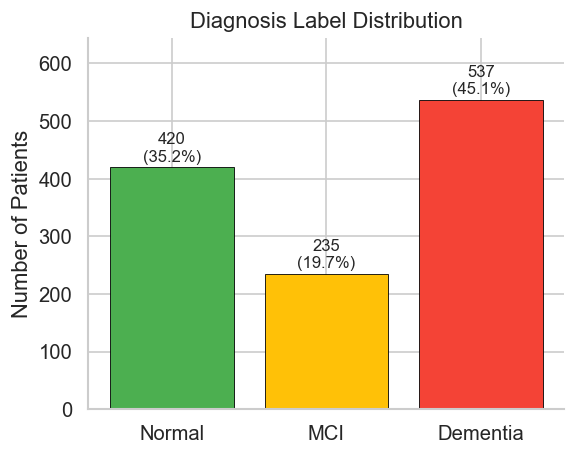

In [25]:
label_counts = obs["label"].value_counts().reindex(["Normal", "MCI", "Dementia"])
label_pct = (label_counts / len(obs) * 100).round(1)

label_summary = pd.DataFrame({"Count": label_counts, "Percentage": label_pct.map(lambda x: f"{x}%")})
display(label_summary)

fig, ax = plt.subplots(figsize=(5, 4))
colors = ["#4CAF50", "#FFC107", "#F44336"]
bars = ax.bar(label_counts.index, label_counts.values, color=colors, edgecolor="black", linewidth=0.5)
for bar, count, pct in zip(bars, label_counts.values, label_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"{count}\n({pct}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Number of Patients")
ax.set_title("Diagnosis Label Distribution")
ax.set_ylim(0, label_counts.max() * 1.2)
sns.despine()
plt.tight_layout()
plt.show()

### 2.2 Sex Distribution

Overall Sex Distribution:


,Count,%
SEX_label,,
Female,668,56.0%
Male,524,44.0%


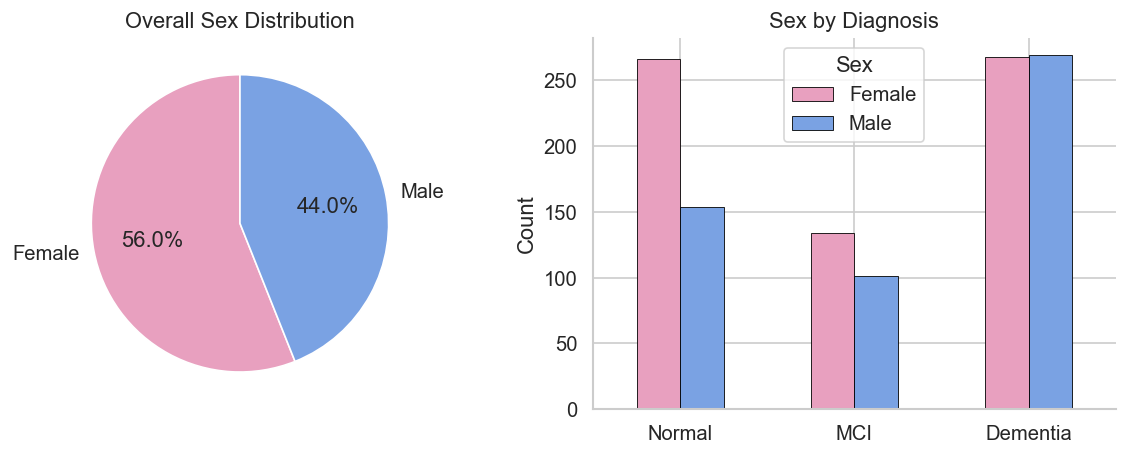

In [26]:
sex_map = {0: "Female", 1: "Male"}
m1["SEX_label"] = m1["SEX"].map(sex_map)

sex_counts = m1["SEX_label"].value_counts()
sex_pct = (sex_counts / len(m1) * 100).round(1)

# Overall
print("Overall Sex Distribution:")
display(pd.DataFrame({"Count": sex_counts, "%": sex_pct.map(lambda x: f"{x}%")}))

# By diagnosis
cohort = m1[["subid", "SEX_label"]].merge(obs[["subid", "label"]], on="subid")
ct = pd.crosstab(cohort["label"], cohort["SEX_label"])
ct = ct.reindex(["Normal", "MCI", "Dementia"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Pie chart
axes[0].pie(sex_counts, labels=sex_counts.index, autopct="%1.1f%%",
            colors=["#E8A0BF", "#7AA2E3"], startangle=90, wedgeprops={"edgecolor": "white"})
axes[0].set_title("Overall Sex Distribution")

# Grouped bar
ct.plot(kind="bar", ax=axes[1], color=["#E8A0BF", "#7AA2E3"], edgecolor="black", linewidth=0.5)
axes[1].set_title("Sex by Diagnosis")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Sex")
sns.despine()
plt.tight_layout()
plt.show()

m1.drop(columns=["SEX_label"], inplace=True)

### 2.3 Race Distribution

Race Distribution:


,Count,%
RACE_label,,
White,981,82.3%
Black/African American,203,17.0%
Asian,4,0.3%
Other/Unknown,2,0.2%
Missing,1,0.1%
American Indian/Alaska Native,1,0.1%


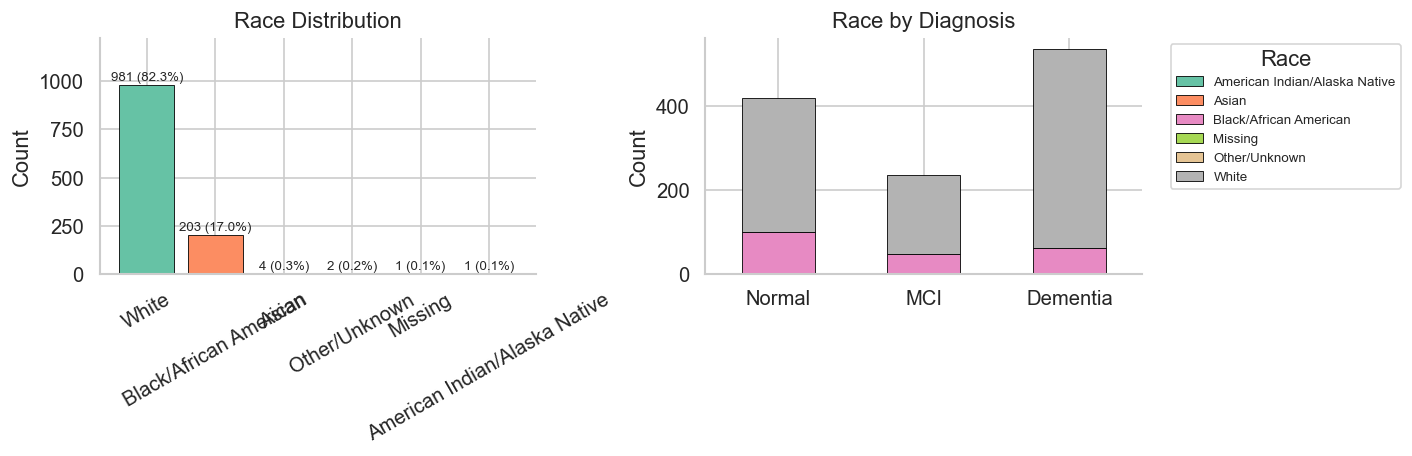

In [27]:
race_map = {1: "White", 2: "Black/African American", 3: "American Indian/Alaska Native",
            5: "Asian", 50: "Other/Unknown"}
m1["RACE_label"] = m1["RACE"].map(race_map).fillna("Missing")

race_counts = m1["RACE_label"].value_counts()
race_pct = (race_counts / len(m1) * 100).round(1)

print("Race Distribution:")
display(pd.DataFrame({"Count": race_counts, "%": race_pct.map(lambda x: f"{x}%")}))

# By diagnosis
cohort = m1[["subid", "RACE_label"]].merge(obs[["subid", "label"]], on="subid")
ct = pd.crosstab(cohort["label"], cohort["RACE_label"])
ct = ct.reindex(["Normal", "MCI", "Dementia"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
palette = sns.color_palette("Set2", n_colors=len(race_counts))
bars = axes[0].bar(race_counts.index, race_counts.values, color=palette, edgecolor="black", linewidth=0.5)
for bar, count, pct in zip(bars, race_counts.values, race_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 f"{count} ({pct}%)", ha="center", va="bottom", fontsize=8)
axes[0].set_ylabel("Count")
axes[0].set_title("Race Distribution")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylim(0, race_counts.max() * 1.25)

# Stacked bar by diagnosis
ct.plot(kind="bar", stacked=True, ax=axes[1], colormap="Set2", edgecolor="black", linewidth=0.5)
axes[1].set_title("Race by Diagnosis")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Race", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

m1.drop(columns=["RACE_label"], inplace=True)

### 2.4 Age Group Distribution

Age Group Distribution:


,Count,%
age_group,,
<50,84,7.0%
50–65,324,27.2%
65–75,398,33.4%
75+,386,32.4%


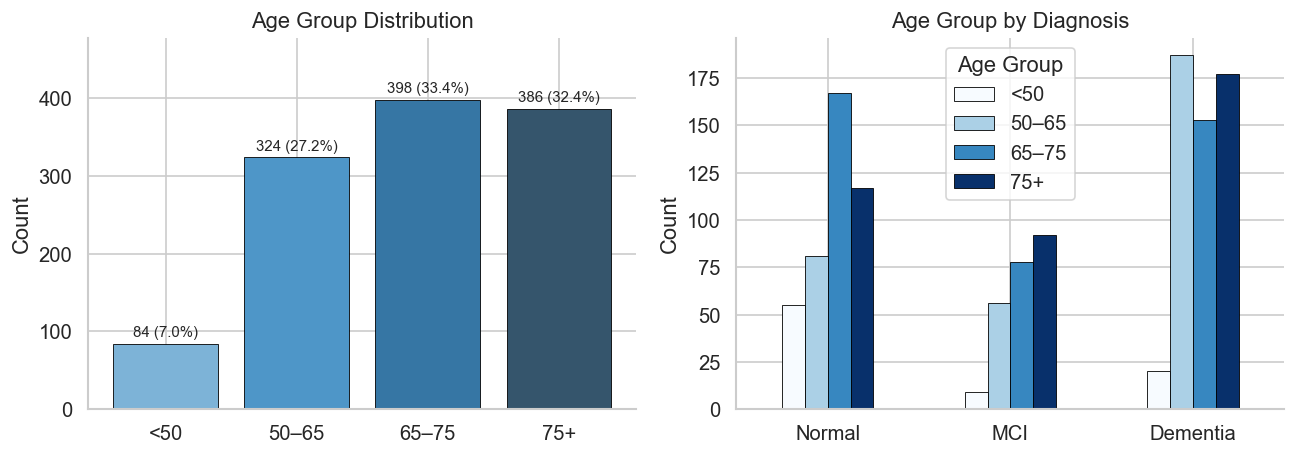

In [28]:
age_cols = ["age<50", "age_50-65", "age_65-75", "age_75+"]
age_labels = ["<50", "50–65", "65–75", "75+"]

# Derive age group per patient
m1["age_group"] = m1[age_cols].idxmax(axis=1).map(dict(zip(age_cols, age_labels)))

age_counts = m1["age_group"].value_counts().reindex(age_labels)
age_pct = (age_counts / len(m1) * 100).round(1)

print("Age Group Distribution:")
display(pd.DataFrame({"Count": age_counts, "%": age_pct.map(lambda x: f"{x}%")}))

# By diagnosis
cohort = m1[["subid", "age_group"]].merge(obs[["subid", "label"]], on="subid")
ct = pd.crosstab(cohort["label"], cohort["age_group"])
ct = ct.reindex(["Normal", "MCI", "Dementia"])
ct = ct.reindex(columns=age_labels)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Bar chart
palette = sns.color_palette("Blues_d", n_colors=len(age_labels))
bars = axes[0].bar(age_labels, age_counts.values, color=palette, edgecolor="black", linewidth=0.5)
for bar, count, pct in zip(bars, age_counts.values, age_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                 f"{count} ({pct}%)", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("Count")
axes[0].set_title("Age Group Distribution")
axes[0].set_ylim(0, age_counts.max() * 1.2)

# Grouped bar by diagnosis
ct.plot(kind="bar", ax=axes[1], colormap="Blues", edgecolor="black", linewidth=0.5)
axes[1].set_title("Age Group by Diagnosis")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Age Group")
sns.despine()
plt.tight_layout()
plt.show()

m1.drop(columns=["age_group"], inplace=True)

### 2.5 Hispanic/Latino Ethnicity

In [29]:
hisp_map = {0: "Non-Hispanic", 1: "Hispanic/Latino"}
hisp_counts = m1["HISPANIC"].map(hisp_map).value_counts()
hisp_pct = (hisp_counts / len(m1) * 100).round(1)

print("Hispanic/Latino Ethnicity:")
display(pd.DataFrame({"Count": hisp_counts, "%": hisp_pct.map(lambda x: f"{x}%")}))

Hispanic/Latino Ethnicity:


,Count,%
HISPANIC,,
Non-Hispanic,1174,98.5%
Hispanic/Latino,18,1.5%


### 2.6 Cohort Summary Table (Table 1)

In [30]:
def build_table1(obs, m1):
    """Build a Table-1-style cohort summary stratified by diagnosis."""
    merged = m1.merge(obs[["subid", "label"]], on="subid")
    groups = ["Normal", "MCI", "Dementia"]
    rows = []

    # N
    row = {"Characteristic": "N"}
    for g in groups:
        row[g] = str(len(merged[merged["label"] == g]))
    row["Overall"] = str(len(merged))
    rows.append(row)

    # Sex
    for sex_val, sex_name in [(0, "Female"), (1, "Male")]:
        row = {"Characteristic": f"Sex – {sex_name}"}
        for g in groups:
            sub = merged[merged["label"] == g]
            n = (sub["SEX"] == sex_val).sum()
            row[g] = f"{n} ({100*n/len(sub):.1f}%)"
        n_all = (merged["SEX"] == sex_val).sum()
        row["Overall"] = f"{n_all} ({100*n_all/len(merged):.1f}%)"
        rows.append(row)

    # Race
    race_map = {1: "White", 2: "Black/African American", 3: "Amer. Indian/Alaska Native",
                5: "Asian", 50: "Other/Unknown"}
    for race_val, race_name in sorted(race_map.items()):
        row = {"Characteristic": f"Race – {race_name}"}
        for g in groups:
            sub = merged[merged["label"] == g].fillna(50)  # Treat missing as 50 for counting
            n = (sub["RACE"] == race_val).sum()
            row[g] = f"{n} ({100*n/len(sub):.1f}%)"
        n_all = (merged["RACE"].fillna(50) == race_val).sum()
        row["Overall"] = f"{n_all} ({100*n_all/len(merged):.1f}%)"
        rows.append(row)

    # Age group
    age_cols = ["age<50", "age_50-65", "age_65-75", "age_75+"]
    age_labels_map = {"age<50": "<50", "age_50-65": "50–65", "age_65-75": "65–75", "age_75+": "75+"}
    for col in age_cols:
        row = {"Characteristic": f"Age – {age_labels_map[col]}"}
        for g in groups:
            sub = merged[merged["label"] == g]
            n = (sub[col] == 1).sum()
            row[g] = f"{n} ({100*n/len(sub):.1f}%)"
        n_all = (merged[col] == 1).sum()
        row["Overall"] = f"{n_all} ({100*n_all/len(merged):.1f}%)"
        rows.append(row)

    # Hispanic
    row = {"Characteristic": "Hispanic/Latino"}
    for g in groups:
        sub = merged[merged["label"] == g]
        n = (sub["HISPANIC"] == 1).sum()
        row[g] = f"{n} ({100*n/len(sub):.1f}%)"
    n_all = (merged["HISPANIC"] == 1).sum()
    row["Overall"] = f"{n_all} ({100*n_all/len(merged):.1f}%)"
    rows.append(row)

    return pd.DataFrame(rows).set_index("Characteristic")

table1 = build_table1(obs, m1)
display(table1)

,Normal,MCI,Dementia,Overall
Characteristic,,,,
N,420,235,537,1192
Sex – Female,266 (63.3%),134 (57.0%),268 (49.9%),668 (56.0%)
Sex – Male,154 (36.7%),101 (43.0%),269 (50.1%),524 (44.0%)
Race – White,319 (76.0%),187 (79.6%),475 (88.5%),981 (82.3%)
Race – Black/African American,98 (23.3%),47 (20.0%),58 (10.8%),203 (17.0%)
Race – Amer. Indian/Alaska Native,0 (0.0%),0 (0.0%),1 (0.2%),1 (0.1%)
Race – Asian,1 (0.2%),1 (0.4%),2 (0.4%),4 (0.3%)
Race – Other/Unknown,2 (0.5%),0 (0.0%),1 (0.2%),3 (0.3%)
Age – <50,55 (13.1%),9 (3.8%),20 (3.7%),84 (7.0%)


---
## 3. Missingness Analysis

### 3.1 Per-Column Missingness by Modality

In [31]:
def missingness_table(df, name):
    """Return a DataFrame summarising missingness for each feature column."""
    feat_cols = [c for c in df.columns if c != "subid"]
    records = []
    for col in feat_cols:
        n_miss = df[col].isna().sum()
        pct = 100 * n_miss / len(df)
        records.append({"Modality": name, "Feature": col,
                        "N Missing": n_miss, "% Missing": round(pct, 1),
                        "N Present": len(df) - n_miss})
    return pd.DataFrame(records)

miss_all = pd.concat([missingness_table(df, name) for name, df in modalities.items()], ignore_index=True)
display(miss_all.style.background_gradient(subset=["% Missing"], cmap="YlOrRd", vmin=0, vmax=100))

,Modality,Feature,N Missing,% Missing,N Present
0,M1 – Demographics,SEX,0,0.000000,1192
1,M1 – Demographics,HISPANIC,0,0.000000,1192
2,M1 – Demographics,RACE,1,0.100000,1191
3,M1 – Demographics,age<50,0,0.000000,1192
4,M1 – Demographics,age_50-65,0,0.000000,1192
5,M1 – Demographics,age_65-75,0,0.000000,1192
6,M1 – Demographics,age_75+,0,0.000000,1192
7,M2 – Comorbidities,obesity,0,0.000000,1192
8,M2 – Comorbidities,diabetes,0,0.000000,1192
9,M2 – Comorbidities,hyperlipidemia,0,0.000000,1192


### 3.2 Missingness Heatmap (per Modality)

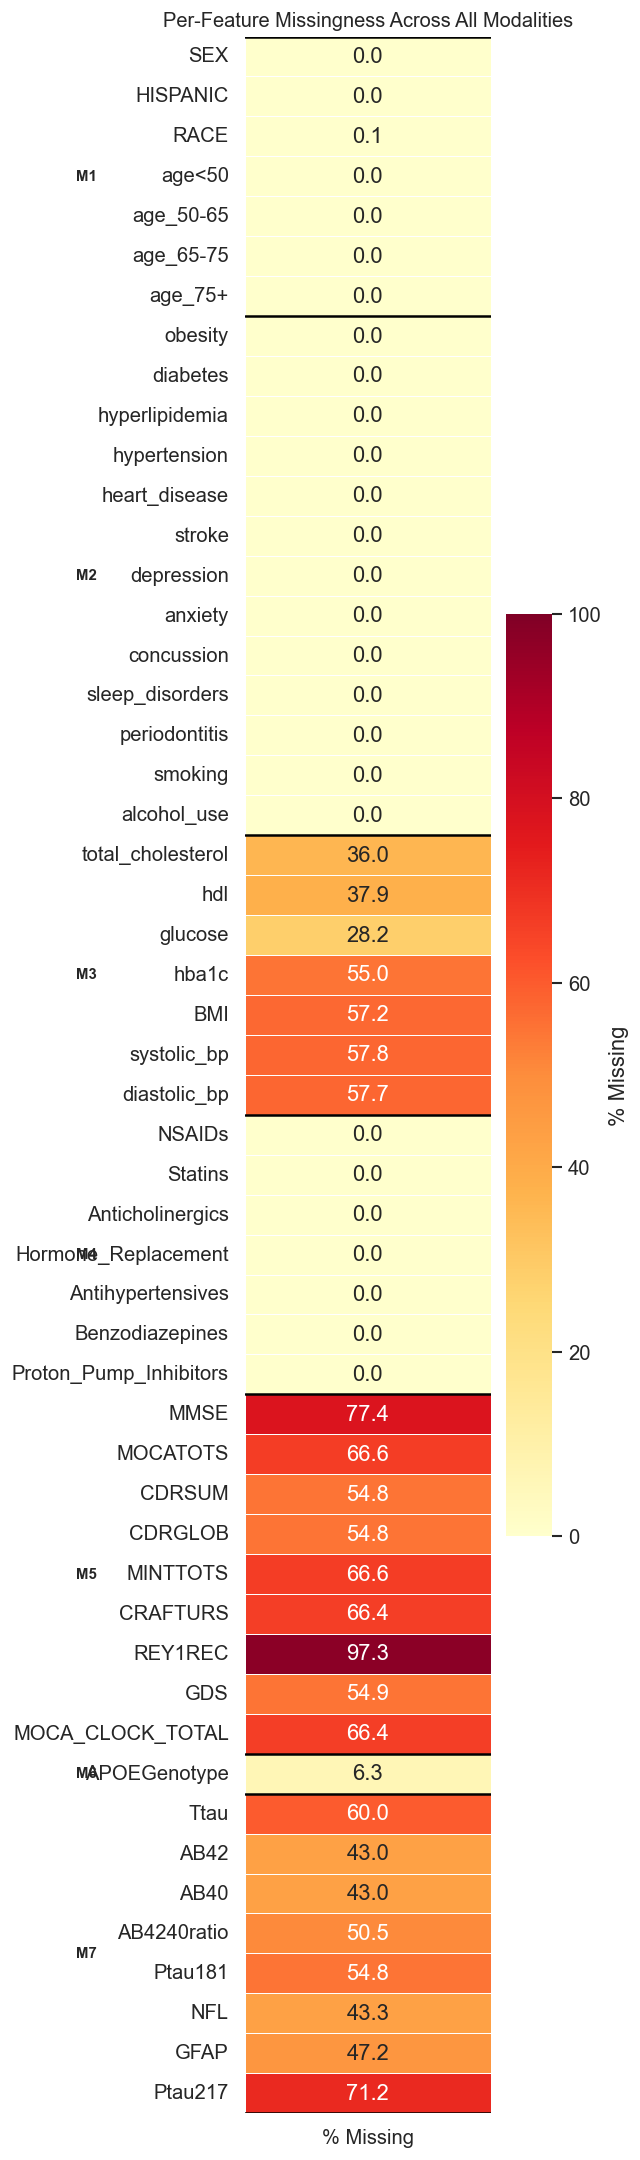

In [32]:
# Build a matrix: rows = features (all modalities), value = % missing
miss_pivot = miss_all.set_index(["Modality", "Feature"])[["% Missing"]]

fig, ax = plt.subplots(figsize=(6, max(4, len(miss_all) * 0.35)))

# Prepare data for heatmap
values = miss_all["% Missing"].values.reshape(-1, 1)

sns.heatmap(values, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            yticklabels=[f"{row['Feature']}" for _, row in miss_all.iterrows()],
            xticklabels=["% Missing"], cbar_kws={"label": "% Missing"},
            linewidths=0.5, ax=ax)

# Add modality group separators
modality_names = miss_all["Modality"].unique()
y_pos = 0
for mod_name in modality_names:
    n_feats = len(miss_all[miss_all["Modality"] == mod_name])
    ax.axhline(y=y_pos, color="black", linewidth=1.5)
    ax.text(-0.6, y_pos + n_feats / 2, mod_name.split(" – ")[0],
            ha="right", va="center", fontsize=9, fontweight="bold")
    y_pos += n_feats
ax.axhline(y=y_pos, color="black", linewidth=1.5)

ax.set_title("Per-Feature Missingness Across All Modalities", fontsize=12)
plt.tight_layout()
plt.show()

### 3.3 Modality-Level Missingness Summary

In [33]:
mod_miss = []
for name, df in modalities.items():
    feat_cols = [c for c in df.columns if c != "subid"]
    feat_df = df[feat_cols]
    # Patient has modality = at least one non-NaN feature
    n_patients_present = feat_df.notna().any(axis=1).sum()
    n_patients_missing = len(df) - n_patients_present
    total_cells = feat_df.size
    total_missing = feat_df.isna().sum().sum()
    mod_miss.append({
        "Modality": name,
        "Features": len(feat_cols),
        "Patients with data": n_patients_present,
        "Patients fully missing": n_patients_missing,
        "% Patients missing": round(100 * n_patients_missing / len(df), 1),
        "Total cells": total_cells,
        "Missing cells": total_missing,
        "% Cells missing": round(100 * total_missing / total_cells, 1) if total_cells > 0 else 0,
    })

mod_miss_df = pd.DataFrame(mod_miss)
display(mod_miss_df.style.background_gradient(subset=["% Cells missing"], cmap="YlOrRd", vmin=0, vmax=100))

,Modality,Features,Patients with data,Patients fully missing,% Patients missing,Total cells,Missing cells,% Cells missing
0,M1 – Demographics,7,1192,0,0.000000,8344,1,0.000000
1,M2 – Comorbidities,13,1192,0,0.000000,15496,0,0.000000
2,M3 – Lab Tests,7,1039,153,12.800000,8344,3932,47.100000
3,M4 – Medications,7,1192,0,0.000000,8344,0,0.000000
4,M5 – Cognitive Scores,9,539,653,54.800000,10728,7216,67.300000
5,M6 – APOE,1,1117,75,6.300000,1192,75,6.300000
6,M7 – Proteins,8,682,510,42.800000,9536,4922,51.600000


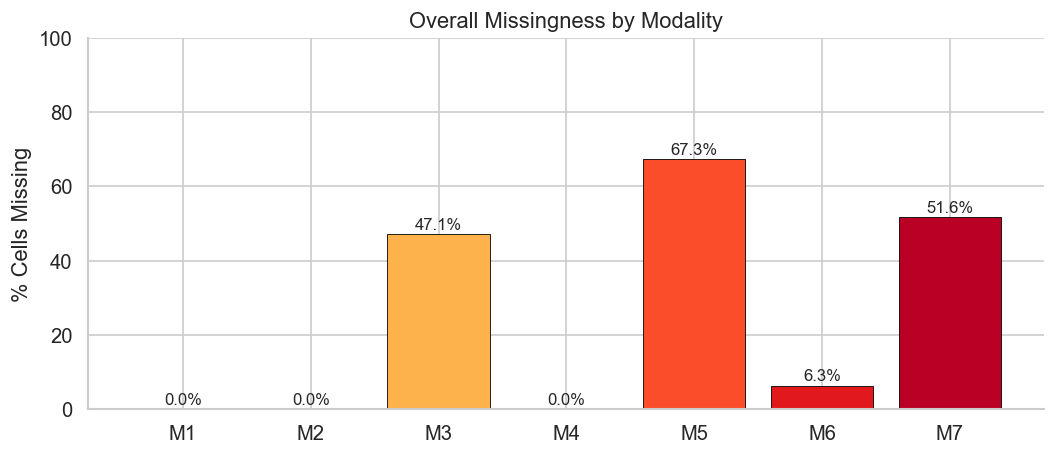

In [34]:
fig, ax = plt.subplots(figsize=(9, 4))
short_names = [n.split(" – ")[0] for n in mod_miss_df["Modality"]]
bars = ax.bar(short_names, mod_miss_df["% Cells missing"],
              color=sns.color_palette("YlOrRd", n_colors=len(mod_miss_df)),
              edgecolor="black", linewidth=0.5)
for bar, pct in zip(bars, mod_miss_df["% Cells missing"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
            f"{pct}%", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("% Cells Missing")
ax.set_title("Overall Missingness by Modality")
ax.set_ylim(0, 100)
sns.despine()
plt.tight_layout()
plt.show()

### 3.4 Patient-Level Missingness Pattern

Patient-Level Missingness per Modality:


,Features,All missing,Some missing,No missing
Modality,,,,
M1 – Demographics,7,0 (0.0%),1 (0.1%),1191 (99.9%)
M2 – Comorbidities,13,0 (0.0%),0 (0.0%),1192 (100.0%)
M3 – Lab Tests,7,153 (12.8%),800 (67.1%),239 (20.1%)
M4 – Medications,7,0 (0.0%),0 (0.0%),1192 (100.0%)
M5 – Cognitive Scores,9,653 (54.8%),529 (44.4%),10 (0.8%)
M6 – APOE,1,75 (6.3%),0 (0.0%),1117 (93.7%)
M7 – Proteins,8,510 (42.8%),506 (42.4%),176 (14.8%)


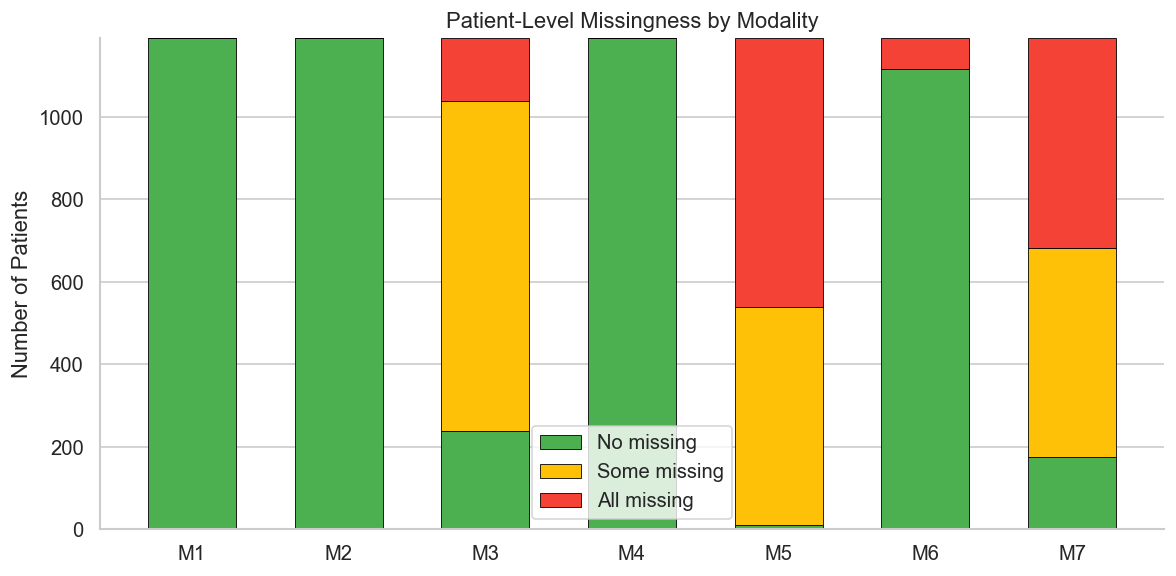


Number of modalities available per patient:


,Count
Modalities available,
3,18
4,135
5,269
6,376
7,394


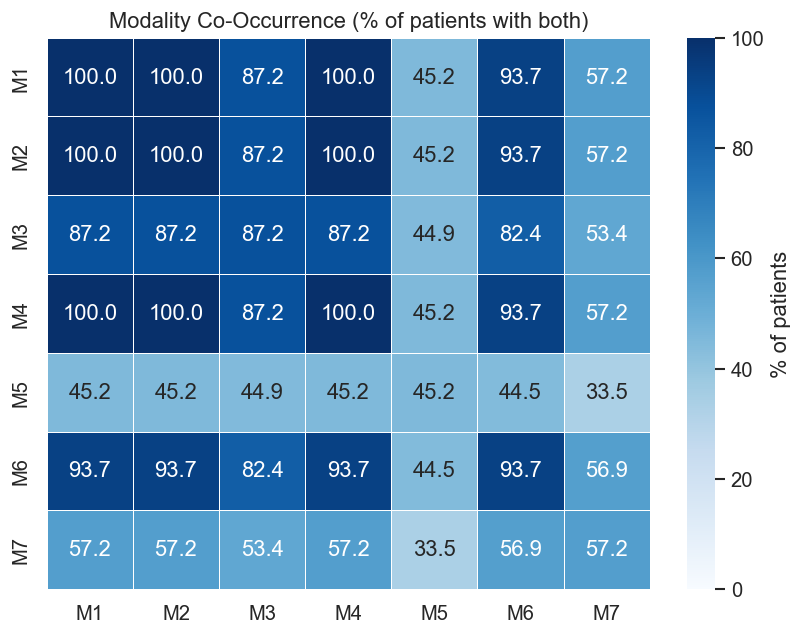

In [35]:
# For each patient, classify missingness per modality: All missing, Some missing, No missing
label_map = obs.set_index("subid")["label"]

records = []
for name, df in modalities.items():
    feat_cols = [c for c in df.columns if c != "subid"]
    feat_df = df[feat_cols]
    n_feats = len(feat_cols)
    n_missing_per_patient = feat_df.isna().sum(axis=1)

    all_missing = (n_missing_per_patient == n_feats).sum()
    some_missing = ((n_missing_per_patient > 0) & (n_missing_per_patient < n_feats)).sum()
    no_missing = (n_missing_per_patient == 0).sum()

    short = name.split(" – ")[0]
    records.append({
        "Modality": name,
        "Features": n_feats,
        "All missing": f"{all_missing} ({100*all_missing/len(df):.1f}%)",
        "Some missing": f"{some_missing} ({100*some_missing/len(df):.1f}%)",
        "No missing": f"{no_missing} ({100*no_missing/len(df):.1f}%)",
    })

patient_miss_df = pd.DataFrame(records).set_index("Modality")
print("Patient-Level Missingness per Modality:")
display(patient_miss_df)

# --- Stacked bar chart ---
fig, ax = plt.subplots(figsize=(10, 5))
short_names = [r.split(" – ")[0] for r in patient_miss_df.index]

# Extract numeric counts
all_vals, some_vals, no_vals = [], [], []
for _, row in patient_miss_df.iterrows():
    all_vals.append(int(row["All missing"].split(" (")[0]))
    some_vals.append(int(row["Some missing"].split(" (")[0]))
    no_vals.append(int(row["No missing"].split(" (")[0]))

x = np.arange(len(short_names))
width = 0.6
bars_no = ax.bar(x, no_vals, width, label="No missing", color="#4CAF50", edgecolor="black", linewidth=0.5)
bars_some = ax.bar(x, some_vals, width, bottom=no_vals, label="Some missing", color="#FFC107", edgecolor="black", linewidth=0.5)
bars_all = ax.bar(x, all_vals, width, bottom=np.array(no_vals)+np.array(some_vals), label="All missing", color="#F44336", edgecolor="black", linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(short_names)
ax.set_ylabel("Number of Patients")
ax.set_title("Patient-Level Missingness by Modality")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

# --- Co-occurrence matrix ---
patient_mod_presence = pd.DataFrame({"subid": obs["subid"]})
for name, df in modalities.items():
    feat_cols = [c for c in df.columns if c != "subid"]
    presence = df.set_index("subid")[feat_cols].notna().any(axis=1).astype(int)
    short = name.split(" – ")[0]
    patient_mod_presence[short] = patient_mod_presence["subid"].map(presence).fillna(0).astype(int)

mod_cols = [c for c in patient_mod_presence.columns if c != "subid"]
patient_mod_presence["Modalities available"] = patient_mod_presence[mod_cols].sum(axis=1)

print("\nNumber of modalities available per patient:")
display(patient_mod_presence["Modalities available"].value_counts().sort_index().to_frame("Count"))

co_matrix = patient_mod_presence[mod_cols].T.dot(patient_mod_presence[mod_cols])
co_pct = (co_matrix / len(patient_mod_presence) * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(co_pct, annot=True, fmt=".1f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={"label": "% of patients"})
ax.set_title("Modality Co-Occurrence (% of patients with both)")
plt.tight_layout()
plt.show()

---
## 4. Feature Distributions by Modality

### 4.1 M1 – Demographics (Binary Features)

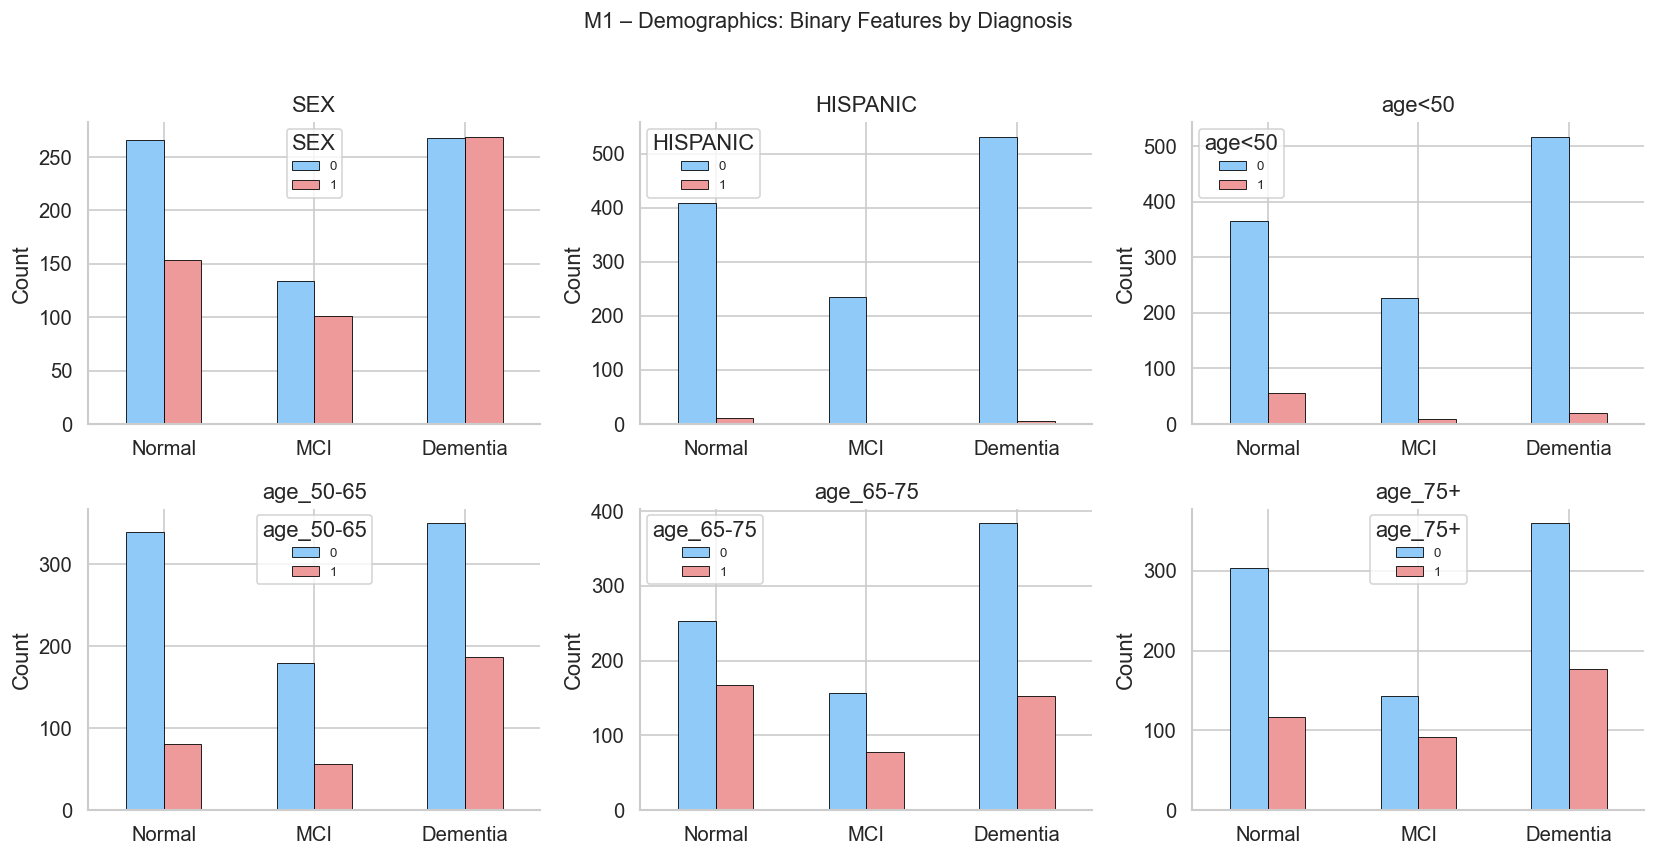

In [36]:
binary_cols_m1 = ["SEX", "HISPANIC", "age<50", "age_50-65", "age_65-75", "age_75+"]
label_map = obs.set_index("subid")["label"]
m1_merged = m1.copy()
m1_merged["label"] = m1_merged["subid"].map(label_map)
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = {"Normal": "#4CAF50", "MCI": "#FFC107", "Dementia": "#F44336"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, binary_cols_m1):
    ct = pd.crosstab(m1_merged["label"], m1_merged[col])
    ct = ct.reindex(diag_order)
    ct.plot(kind="bar", ax=ax, color=["#90CAF9", "#EF9A9A"], edgecolor="black", linewidth=0.5, legend=False)
    ax.set_title(col)
    ax.set_ylabel("Count")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title=col, labels=["0", "1"], fontsize=8)
sns.despine()
plt.suptitle("M1 – Demographics: Binary Features by Diagnosis", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 4.2 M2 – Comorbidities (Binary Features)

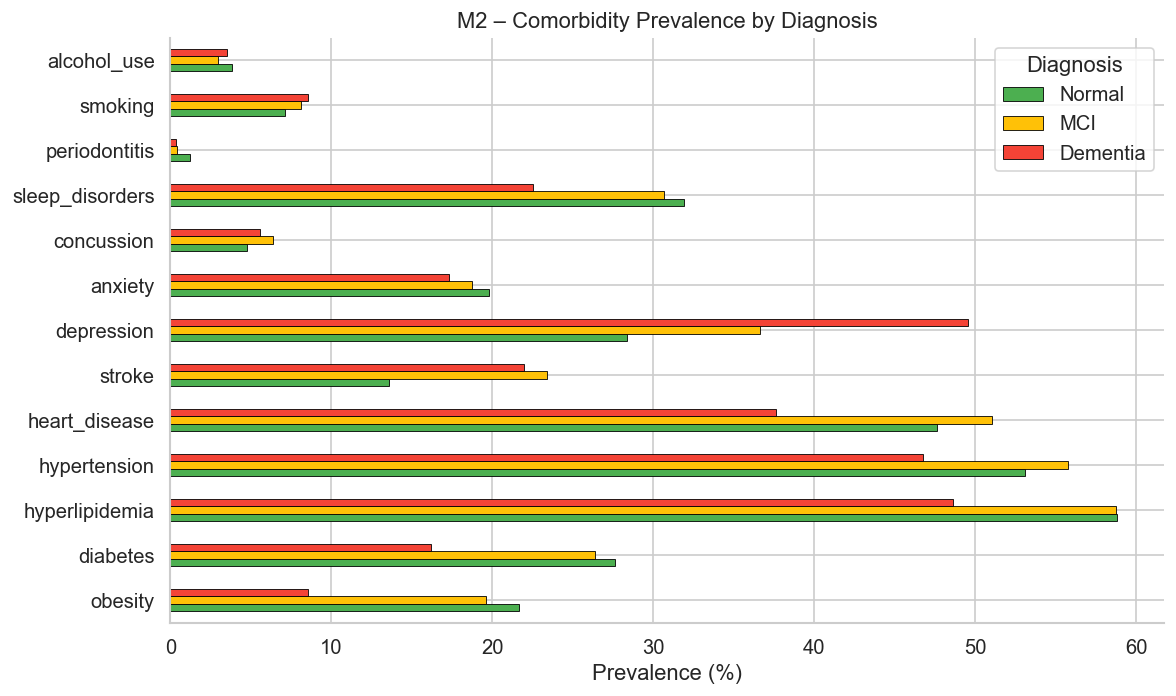

M2 – Comorbidity Prevalence (%) by Diagnosis:


label,Normal,MCI,Dementia
obesity,21.7,19.6,8.6
diabetes,27.6,26.4,16.2
hyperlipidemia,58.8,58.7,48.6
hypertension,53.1,55.7,46.7
heart_disease,47.6,51.1,37.6
stroke,13.6,23.4,22.0
depression,28.3,36.6,49.5
anxiety,19.8,18.7,17.3
concussion,4.8,6.4,5.6
sleep_disorders,31.9,30.6,22.5


In [37]:
m2_cols = [c for c in m2.columns if c != "subid"]
m2_merged = m2.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = ["#4CAF50", "#FFC107", "#F44336"]

# Prevalence by diagnosis
prev_by_diag = m2_merged.groupby("label")[m2_cols].mean().reindex(diag_order) * 100

fig, ax = plt.subplots(figsize=(10, 6))
prev_by_diag.T.plot(kind="barh", ax=ax, color=diag_colors, edgecolor="black", linewidth=0.5)
ax.set_xlabel("Prevalence (%)")
ax.set_title("M2 – Comorbidity Prevalence by Diagnosis")
ax.legend(title="Diagnosis")
sns.despine()
plt.tight_layout()
plt.show()

# Table
print("M2 – Comorbidity Prevalence (%) by Diagnosis:")
display(prev_by_diag.round(1).T)

### 4.3 M3 – Lab Tests (Continuous)

M3 – Lab Tests: Descriptive Statistics by Diagnosis (observed values only)

--- Normal (n=420) ---


,total_cholesterol,hdl,glucose,hba1c,BMI,systolic_bp,diastolic_bp
count,299.00,295.00,312.00,220.00,325.00,317.00,321.00
mean,178.94,56.09,98.77,5.79,28.85,134.44,76.23
std,39.23,14.88,14.71,0.52,5.46,17.70,8.88
min,75.00,23.00,62.00,4.50,13.73,92.00,51.00
25%,152.00,45.00,88.00,5.48,24.66,123.00,71.00
50%,178.00,55.00,96.00,5.70,28.35,133.00,76.00
75%,205.00,66.00,106.00,6.00,32.51,145.00,82.00
max,286.00,93.00,146.00,7.20,43.60,188.00,102.00



--- MCI (n=235) ---


,total_cholesterol,hdl,glucose,hba1c,BMI,systolic_bp,diastolic_bp
count,165.00,159.00,169.00,111.00,62.00,62.00,62.00
mean,173.67,54.69,98.45,5.91,28.21,138.44,72.87
std,36.98,15.40,15.39,0.50,5.64,19.65,9.63
min,93.00,27.00,58.00,4.60,13.67,95.00,54.00
25%,150.00,44.00,89.00,5.60,23.75,128.25,66.00
50%,170.00,51.00,96.00,5.80,28.02,136.50,73.00
75%,200.00,65.00,106.00,6.20,31.91,146.50,78.75
max,285.00,93.00,142.00,7.20,39.86,190.00,96.00



--- Dementia (n=537) ---


,total_cholesterol,hdl,glucose,hba1c,BMI,systolic_bp,diastolic_bp
count,299.00,286.00,375.00,205.00,123.00,124.00,121.00
mean,177.75,51.62,99.51,5.81,26.52,134.56,74.20
std,37.80,13.91,16.89,0.49,5.25,19.00,9.51
min,101.00,26.00,62.00,4.60,14.93,100.00,54.00
25%,149.00,42.00,88.50,5.50,22.80,120.00,69.00
50%,178.00,49.00,97.00,5.70,25.94,133.50,73.00
75%,206.00,59.75,109.00,6.10,29.21,149.25,80.00
max,275.00,92.00,146.00,7.10,44.11,179.00,100.00


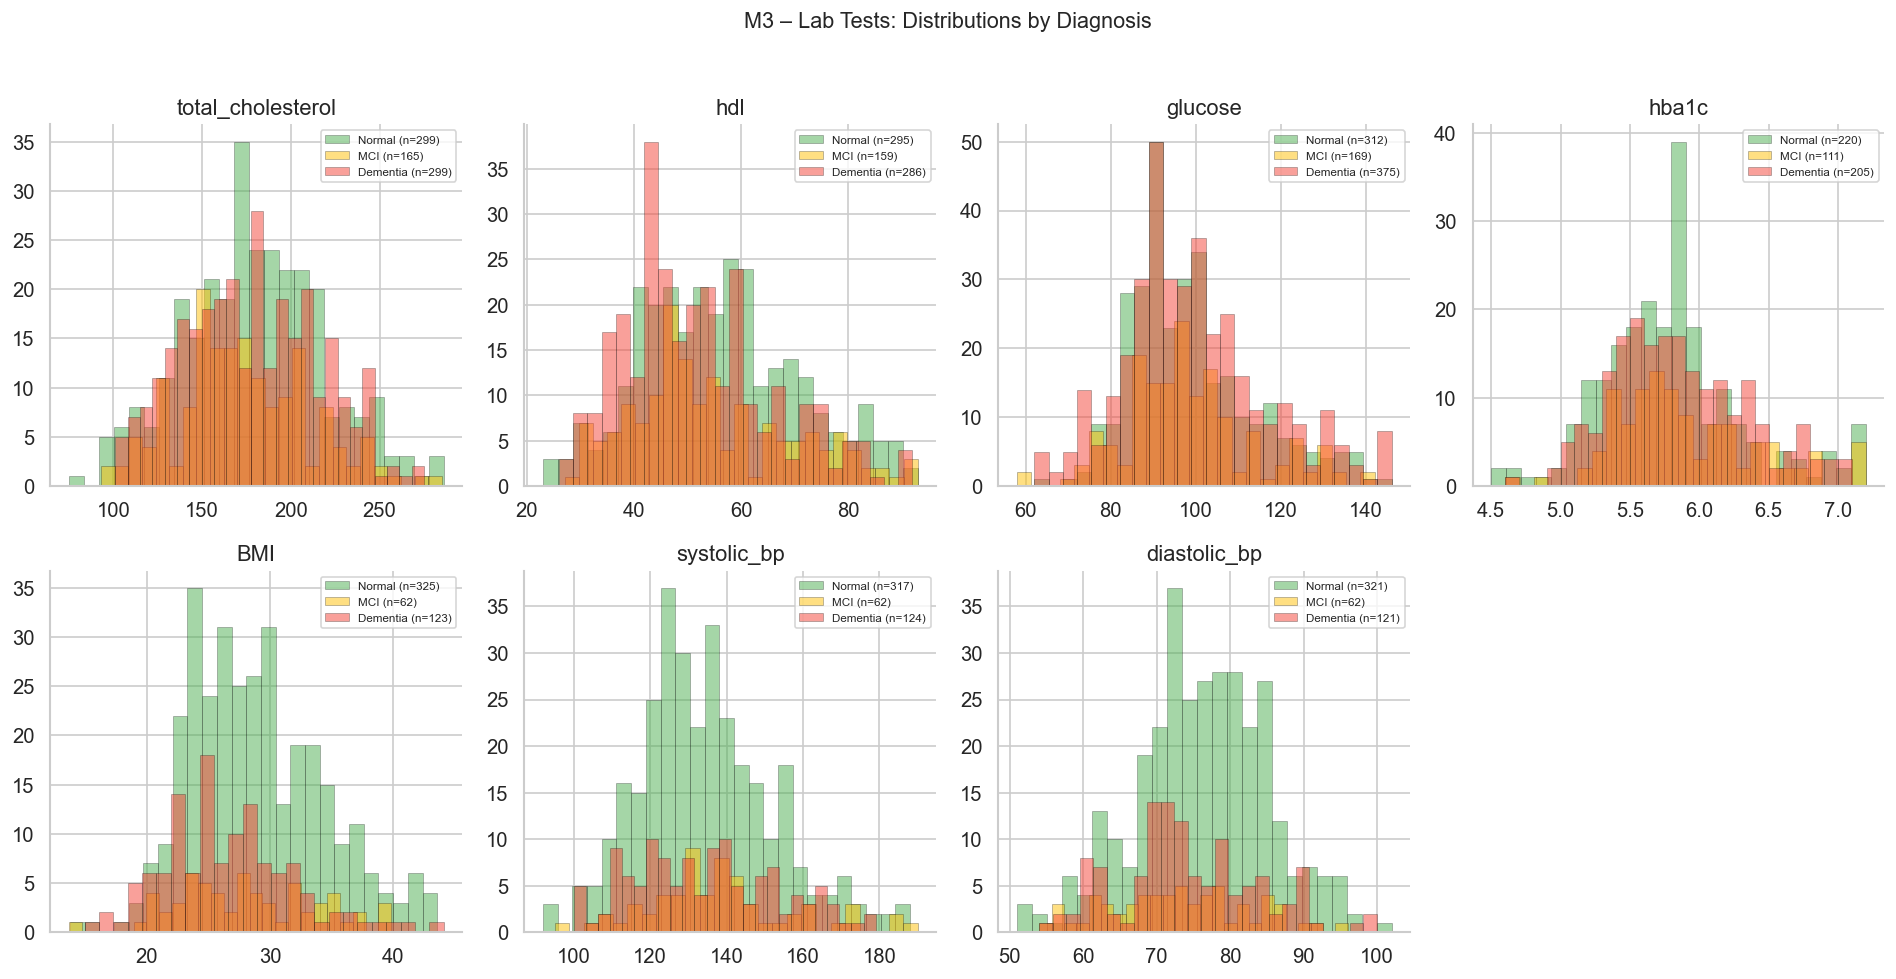

In [38]:
m3_cols = [c for c in m3.columns if c != "subid"]
m3_merged = m3.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = {"Normal": "#4CAF50", "MCI": "#FFC107", "Dementia": "#F44336"}

# Descriptive stats by diagnosis
print("M3 – Lab Tests: Descriptive Statistics by Diagnosis (observed values only)")
for g in diag_order:
    sub = m3_merged[m3_merged["label"] == g][m3_cols]
    print(f"\n--- {g} (n={len(sub)}) ---")
    display(sub.describe().round(2))

# Overlaid histograms
n_cols = len(m3_cols)
ncols_plot = 4
nrows_plot = (n_cols + ncols_plot - 1) // ncols_plot
fig, axes = plt.subplots(nrows_plot, ncols_plot, figsize=(16, 4 * nrows_plot))
axes_flat = axes.flat
for i, col in enumerate(m3_cols):
    ax = axes_flat[i]
    for g in diag_order:
        data = m3_merged[m3_merged["label"] == g][col].dropna()
        ax.hist(data, bins=25, alpha=0.5, color=diag_colors[g], edgecolor="black",
                linewidth=0.3, label=f"{g} (n={len(data)})")
    ax.set_title(col)
    ax.legend(fontsize=7)
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)
plt.suptitle("M3 – Lab Tests: Distributions by Diagnosis", fontsize=13, y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

### 4.4 M4 – Medications (Binary Features)

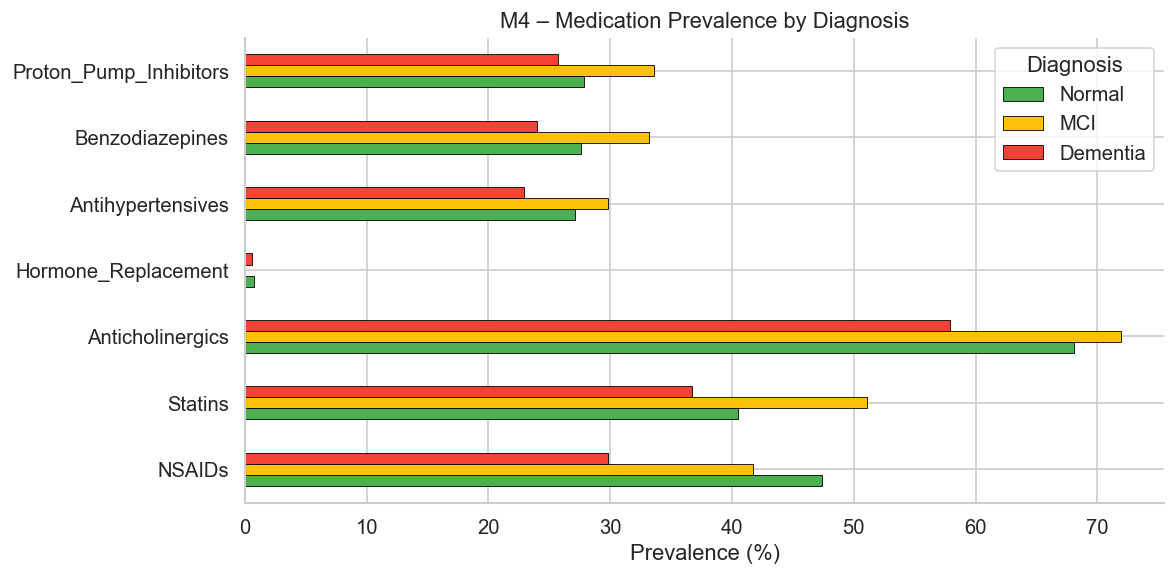

M4 – Medication Prevalence (%) by Diagnosis:


label,Normal,MCI,Dementia
NSAIDs,47.4,41.7,29.8
Statins,40.5,51.1,36.7
Anticholinergics,68.1,71.9,57.9
Hormone_Replacement,0.7,0.0,0.6
Antihypertensives,27.1,29.8,22.9
Benzodiazepines,27.6,33.2,24.0
Proton_Pump_Inhibitors,27.9,33.6,25.7


In [39]:
m4_cols = [c for c in m4.columns if c != "subid"]
m4_merged = m4.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = ["#4CAF50", "#FFC107", "#F44336"]

prev_by_diag_m4 = m4_merged.groupby("label")[m4_cols].mean().reindex(diag_order) * 100

fig, ax = plt.subplots(figsize=(10, 5))
prev_by_diag_m4.T.plot(kind="barh", ax=ax, color=diag_colors, edgecolor="black", linewidth=0.5)
ax.set_xlabel("Prevalence (%)")
ax.set_title("M4 – Medication Prevalence by Diagnosis")
ax.legend(title="Diagnosis")
sns.despine()
plt.tight_layout()
plt.show()

print("M4 – Medication Prevalence (%) by Diagnosis:")
display(prev_by_diag_m4.round(1).T)

### 4.5 M5 – Cognitive Scores (Continuous)

M5 – Cognitive Scores: Descriptive Statistics by Diagnosis (observed values only)

--- Normal (n=420) ---


,MMSE,MOCATOTS,CDRSUM,CDRGLOB,MINTTOTS,CRAFTURS,REY1REC,GDS,MOCA_CLOCK_TOTAL
count,159.00,281.00,339.00,339.00,282.00,283.00,26.00,337.00,281.00
mean,28.92,26.57,0.10,0.05,30.25,17.34,5.42,1.62,2.70
std,1.33,2.47,0.33,0.15,1.83,3.59,2.27,2.11,0.51
min,22.00,16.00,0.00,0.00,24.00,5.00,2.00,0.00,1.00
25%,28.00,25.00,0.00,0.00,29.00,15.00,4.00,0.00,2.00
50%,29.00,27.00,0.00,0.00,31.00,17.00,5.00,1.00,3.00
75%,30.00,28.00,0.00,0.00,32.00,20.00,6.00,2.00,3.00
max,30.00,30.00,3.00,0.50,32.00,25.00,13.00,13.00,3.00



--- MCI (n=235) ---


,MMSE,MOCATOTS,CDRSUM,CDRGLOB,MINTTOTS,CRAFTURS,REY1REC,GDS,MOCA_CLOCK_TOTAL
count,42.00,39.00,67.00,67.00,39.00,39.00,4.00,67.00,39.00
mean,28.29,24.36,0.25,0.13,29.26,13.69,4.00,2.00,2.46
std,1.58,3.20,0.47,0.22,3.90,4.12,2.94,2.04,0.64
min,24.00,17.00,0.00,0.00,8.00,3.00,1.00,0.00,1.00
25%,27.25,22.50,0.00,0.00,29.00,11.00,1.75,0.00,2.00
50%,29.00,25.00,0.00,0.00,30.00,14.00,4.00,1.00,3.00
75%,29.00,27.00,0.50,0.25,31.00,16.00,6.25,3.00,3.00
max,30.00,29.00,2.00,0.50,32.00,22.00,7.00,8.00,3.00



--- Dementia (n=537) ---


,MMSE,MOCATOTS,CDRSUM,CDRGLOB,MINTTOTS,CRAFTURS,REY1REC,GDS,MOCA_CLOCK_TOTAL
count,68.00,78.0,133.00,133.00,77.00,78.00,2.00,133.00,80.00
mean,25.85,20.0,2.16,0.52,28.03,9.59,2.50,3.11,2.19
std,2.85,4.0,1.33,0.11,3.41,4.67,0.71,2.62,0.76
min,19.00,7.0,0.50,0.00,16.00,0.00,2.00,0.00,0.00
25%,24.00,18.0,1.00,0.50,27.00,6.25,2.25,1.00,2.00
50%,26.00,20.0,2.00,0.50,29.00,10.00,2.50,2.00,2.00
75%,28.00,23.0,3.00,0.50,31.00,12.00,2.75,5.00,3.00
max,30.00,27.0,8.00,1.00,32.00,20.00,3.00,12.00,3.00


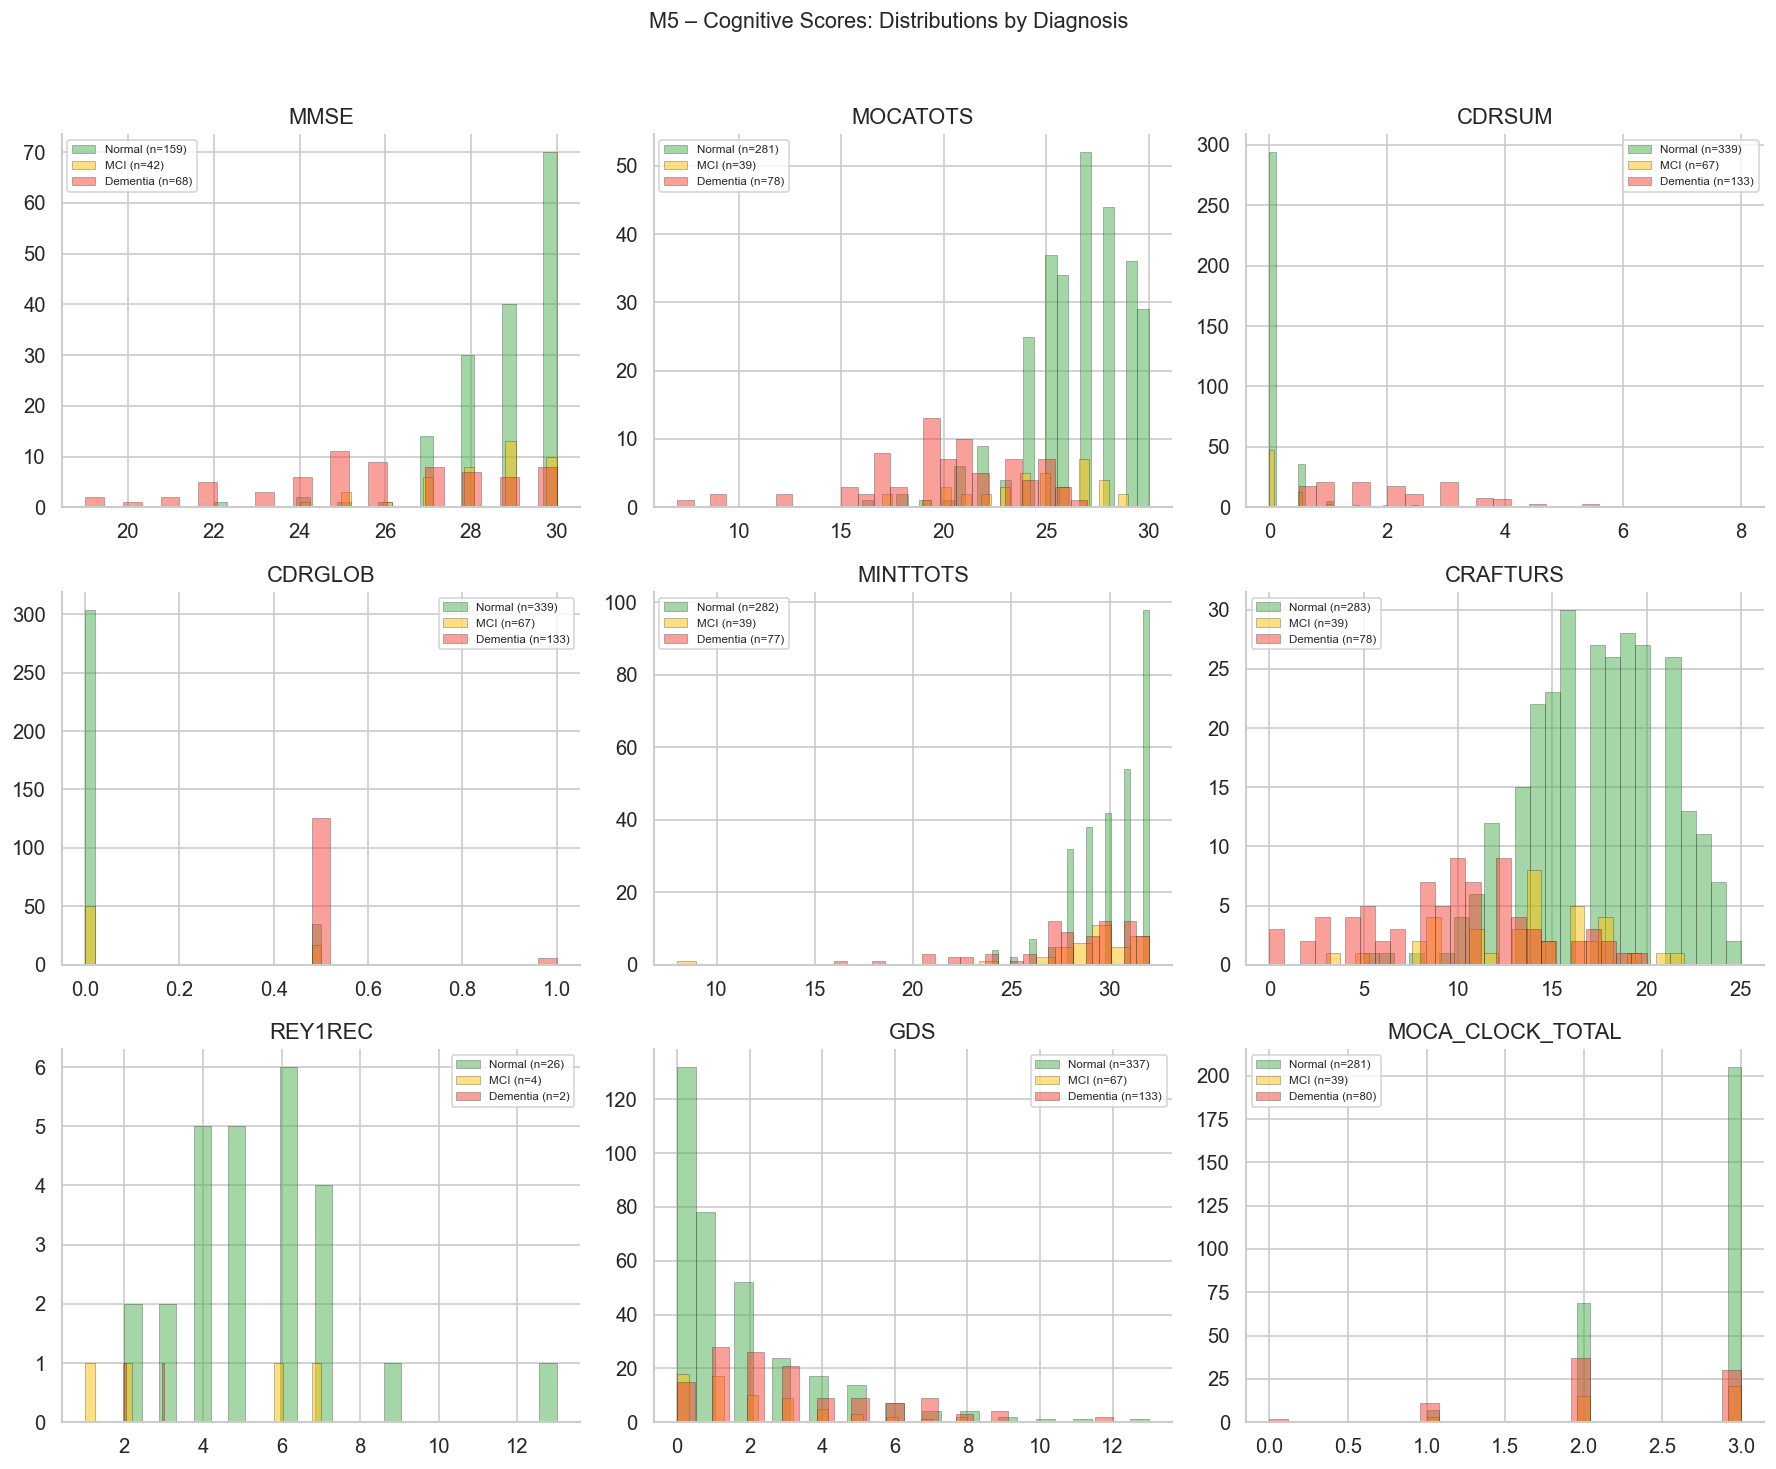

In [40]:
m5_cols = [c for c in m5.columns if c != "subid"]
m5_merged = m5.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = {"Normal": "#4CAF50", "MCI": "#FFC107", "Dementia": "#F44336"}

# Descriptive stats by diagnosis
print("M5 – Cognitive Scores: Descriptive Statistics by Diagnosis (observed values only)")
for g in diag_order:
    sub = m5_merged[m5_merged["label"] == g][m5_cols]
    print(f"\n--- {g} (n={len(sub)}) ---")
    display(sub.describe().round(2))

# Overlaid histograms
n_cols = len(m5_cols)
ncols_plot = 3
nrows_plot = (n_cols + ncols_plot - 1) // ncols_plot
fig, axes = plt.subplots(nrows_plot, ncols_plot, figsize=(15, 4 * nrows_plot))
axes_flat = axes.flat
for i, col in enumerate(m5_cols):
    ax = axes_flat[i]
    for g in diag_order:
        data = m5_merged[m5_merged["label"] == g][col].dropna()
        ax.hist(data, bins=25, alpha=0.5, color=diag_colors[g], edgecolor="black",
                linewidth=0.3, label=f"{g} (n={len(data)})")
    ax.set_title(col)
    ax.legend(fontsize=7)
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)
plt.suptitle("M5 – Cognitive Scores: Distributions by Diagnosis", fontsize=13, y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

### 4.6 M6 – APOE Genotype

APOE Genotype (n=1117, missing=75)


,Count,%
APOEGenotype,,
22.0,2,0.2%
23.0,100,8.4%
24.0,24,2.0%
33.0,501,42.0%
34.0,397,33.3%
44.0,93,7.8%


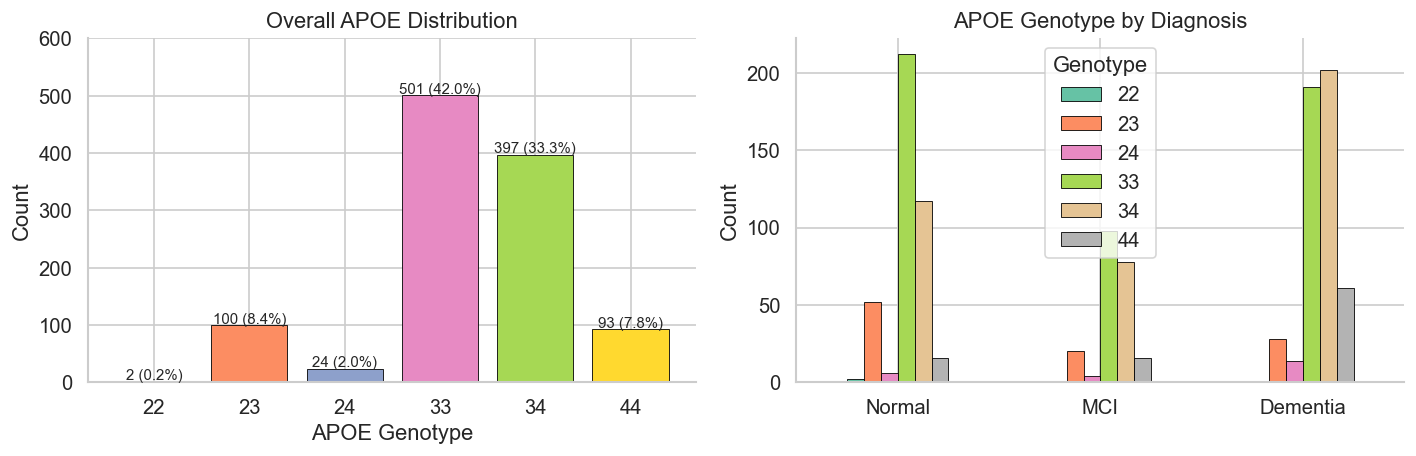


APOE Genotype counts by Diagnosis:


,Missing,22,23,24,33,34,44
label,,,,,,,
Normal,15,2,52,6,212,117,16
MCI,19,0,20,4,98,78,16
Dementia,41,0,28,14,191,202,61


In [41]:
m6_merged = m6.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = ["#4CAF50", "#FFC107", "#F44336"]

apoe_data = m6["APOEGenotype"].dropna()
apoe_counts = apoe_data.value_counts().sort_index()
apoe_pct = (apoe_counts / len(m6) * 100).round(1)

print(f"APOE Genotype (n={len(apoe_data)}, missing={m6['APOEGenotype'].isna().sum()})")
display(pd.DataFrame({"Count": apoe_counts, "%": apoe_pct.map(lambda x: f"{x}%")}))

# Distribution by diagnosis
apoe_by_diag = pd.crosstab(m6_merged["label"], m6_merged["APOEGenotype"].fillna(-1))
apoe_by_diag.columns = [str(int(c)) if c != -1 else "Missing" for c in apoe_by_diag.columns]
apoe_by_diag = apoe_by_diag.reindex(diag_order)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Overall
bars = axes[0].bar(apoe_counts.index.astype(int).astype(str), apoe_counts.values,
              color=sns.color_palette("Set2", n_colors=len(apoe_counts)),
              edgecolor="black", linewidth=0.5)
for bar, cnt, pct in zip(bars, apoe_counts.values, apoe_pct.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 3,
            f"{cnt} ({pct}%)", ha="center", fontsize=9)
axes[0].set_xlabel("APOE Genotype")
axes[0].set_ylabel("Count")
axes[0].set_title("Overall APOE Distribution")
axes[0].set_ylim(0, apoe_counts.max() * 1.2)

# By diagnosis (exclude "Missing" column for clarity)
plot_cols = [c for c in apoe_by_diag.columns if c != "Missing"]
apoe_by_diag[plot_cols].plot(kind="bar", ax=axes[1], colormap="Set2", edgecolor="black", linewidth=0.5)
axes[1].set_title("APOE Genotype by Diagnosis")
axes[1].set_ylabel("Count")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Genotype")
sns.despine()
plt.tight_layout()
plt.show()

# Table: APOE by diagnosis
print("\nAPOE Genotype counts by Diagnosis:")
display(apoe_by_diag)

### 4.7 M7 – Protein Biomarkers (Continuous)

M7 – Protein Biomarkers: Descriptive Statistics by Diagnosis (observed values only)

--- Normal (n=420) ---


,Ttau,AB42,AB40,AB4240ratio,Ptau181,NFL,GFAP,Ptau217
count,184.00,276.00,276.00,230.00,209.00,275.00,254.00,180.00
mean,3.62,48.79,661.14,0.06,5.11,13.73,95.67,0.42
std,2.33,145.87,1986.72,0.02,10.06,12.67,58.89,0.24
min,0.63,2.56,65.80,0.02,0.53,1.49,19.03,0.12
25%,2.51,14.67,228.87,0.05,1.65,7.62,52.19,0.25
50%,3.30,19.59,275.88,0.06,2.43,10.76,85.09,0.34
75%,4.12,24.74,326.39,0.07,3.59,15.98,118.52,0.50
max,27.97,1215.00,16015.00,0.18,80.70,152.86,341.00,1.52



--- MCI (n=235) ---


,Ttau,AB42,AB40,AB4240ratio,Ptau181,NFL,GFAP,Ptau217
count,97.00,142.00,142.00,122.00,109.00,140.00,132.00,76.00
mean,3.74,39.40,600.89,0.06,5.75,20.91,149.92,0.68
std,1.92,147.99,2258.67,0.01,11.20,13.03,86.12,0.40
min,0.74,3.35,65.30,0.02,0.69,3.13,22.62,0.15
25%,2.42,13.42,223.80,0.05,2.31,12.10,90.52,0.38
50%,3.34,19.01,283.02,0.06,3.42,17.64,130.41,0.61
75%,4.76,24.28,347.92,0.07,5.38,26.36,203.11,0.88
max,10.90,1418.00,20670.00,0.10,98.40,79.04,501.63,1.97



--- Dementia (n=537) ---


,Ttau,AB42,AB40,AB4240ratio,Ptau181,NFL,GFAP,Ptau217
count,196.00,262.00,262.00,238.00,221.00,261.00,243.00,87.00
mean,5.16,43.09,702.09,0.06,12.81,37.87,220.16,1.17
std,15.87,130.51,1889.78,0.02,31.08,45.66,243.75,0.68
min,0.81,1.95,56.99,0.01,0.00,5.54,13.35,0.12
25%,2.93,10.35,197.20,0.05,3.11,16.95,115.66,0.63
50%,3.73,15.13,261.95,0.05,5.10,25.64,167.00,1.06
75%,4.96,21.40,314.88,0.06,7.74,40.50,240.57,1.57
max,224.31,1012.00,13760.00,0.10,246.20,542.18,2434.04,2.91


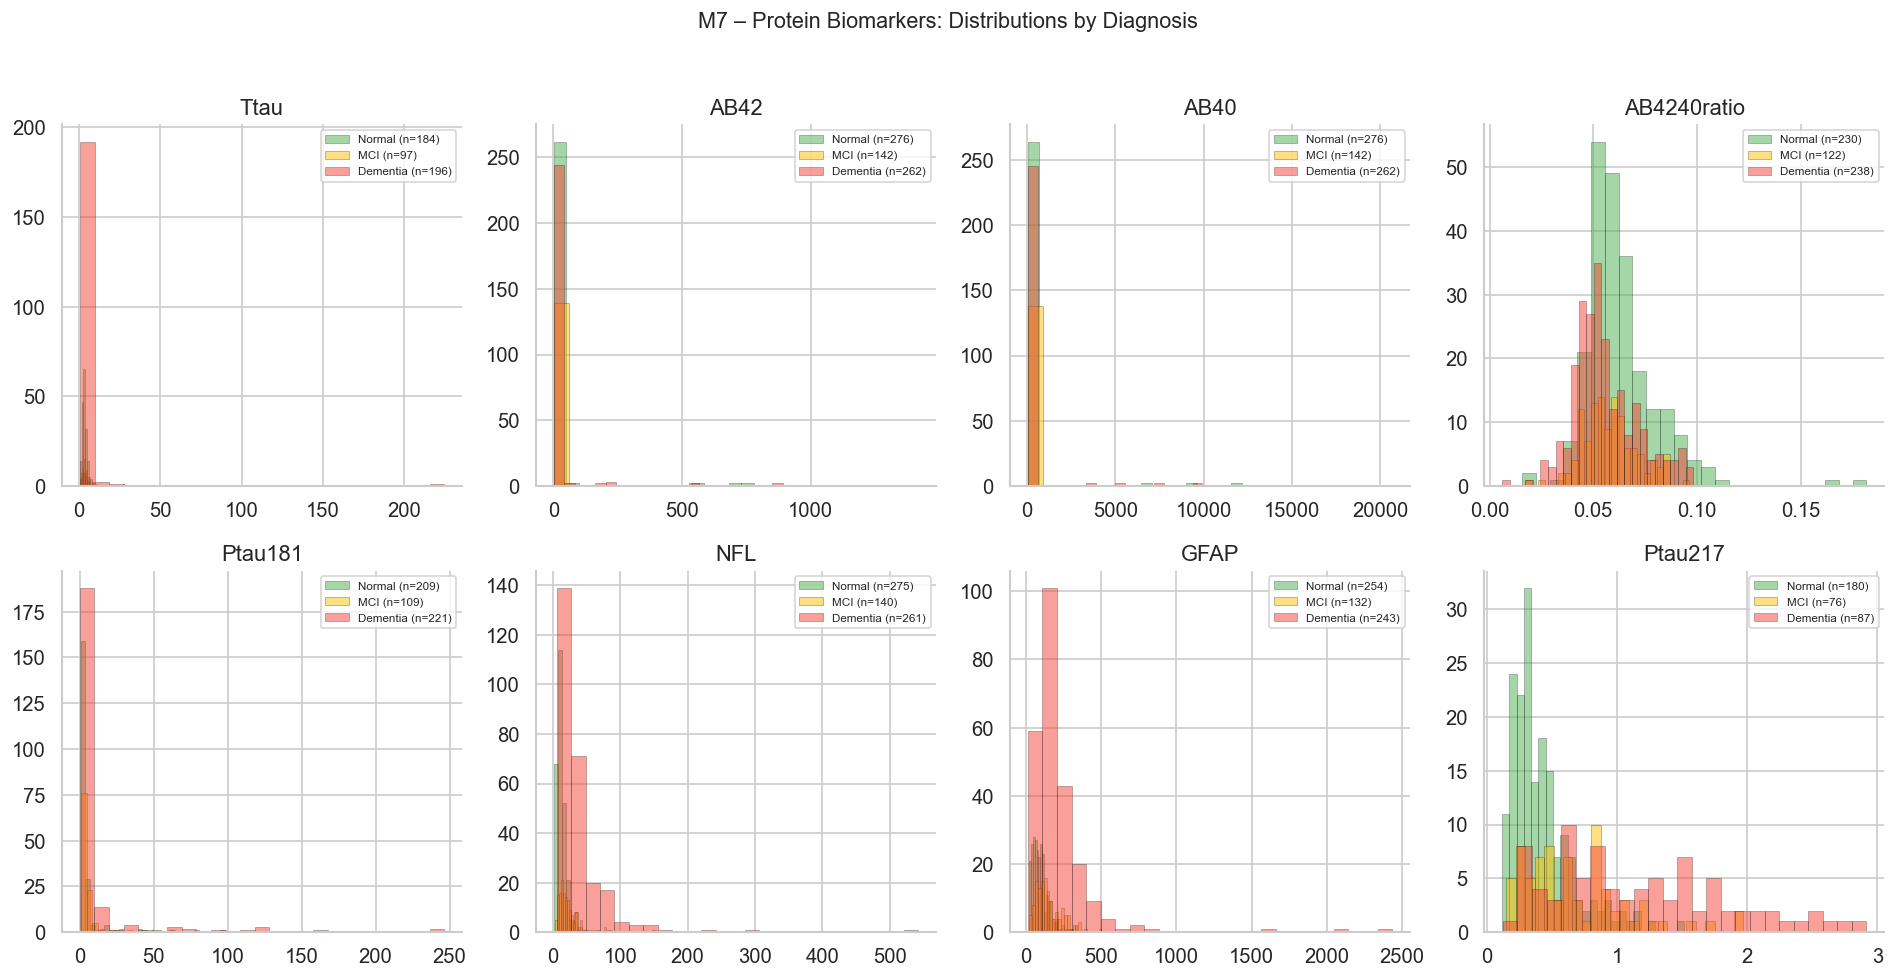

In [42]:
m7_cols = [c for c in m7.columns if c != "subid"]
m7_merged = m7.merge(obs[["subid", "label"]], on="subid")
diag_order = ["Normal", "MCI", "Dementia"]
diag_colors = {"Normal": "#4CAF50", "MCI": "#FFC107", "Dementia": "#F44336"}

# Descriptive stats by diagnosis
print("M7 – Protein Biomarkers: Descriptive Statistics by Diagnosis (observed values only)")
for g in diag_order:
    sub = m7_merged[m7_merged["label"] == g][m7_cols]
    print(f"\n--- {g} (n={len(sub)}) ---")
    display(sub.describe().round(2))

# Overlaid histograms
n_cols = len(m7_cols)
ncols_plot = 4
nrows_plot = (n_cols + ncols_plot - 1) // ncols_plot
fig, axes = plt.subplots(nrows_plot, ncols_plot, figsize=(16, 4 * nrows_plot))
axes_flat = axes.flat
for i, col in enumerate(m7_cols):
    ax = axes_flat[i]
    for g in diag_order:
        data = m7_merged[m7_merged["label"] == g][col].dropna()
        ax.hist(data, bins=25, alpha=0.5, color=diag_colors[g], edgecolor="black",
                linewidth=0.3, label=f"{g} (n={len(data)})")
    ax.set_title(col)
    ax.legend(fontsize=7)
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)
plt.suptitle("M7 – Protein Biomarkers: Distributions by Diagnosis", fontsize=13, y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

---
## 5. Missingness by Diagnosis Group

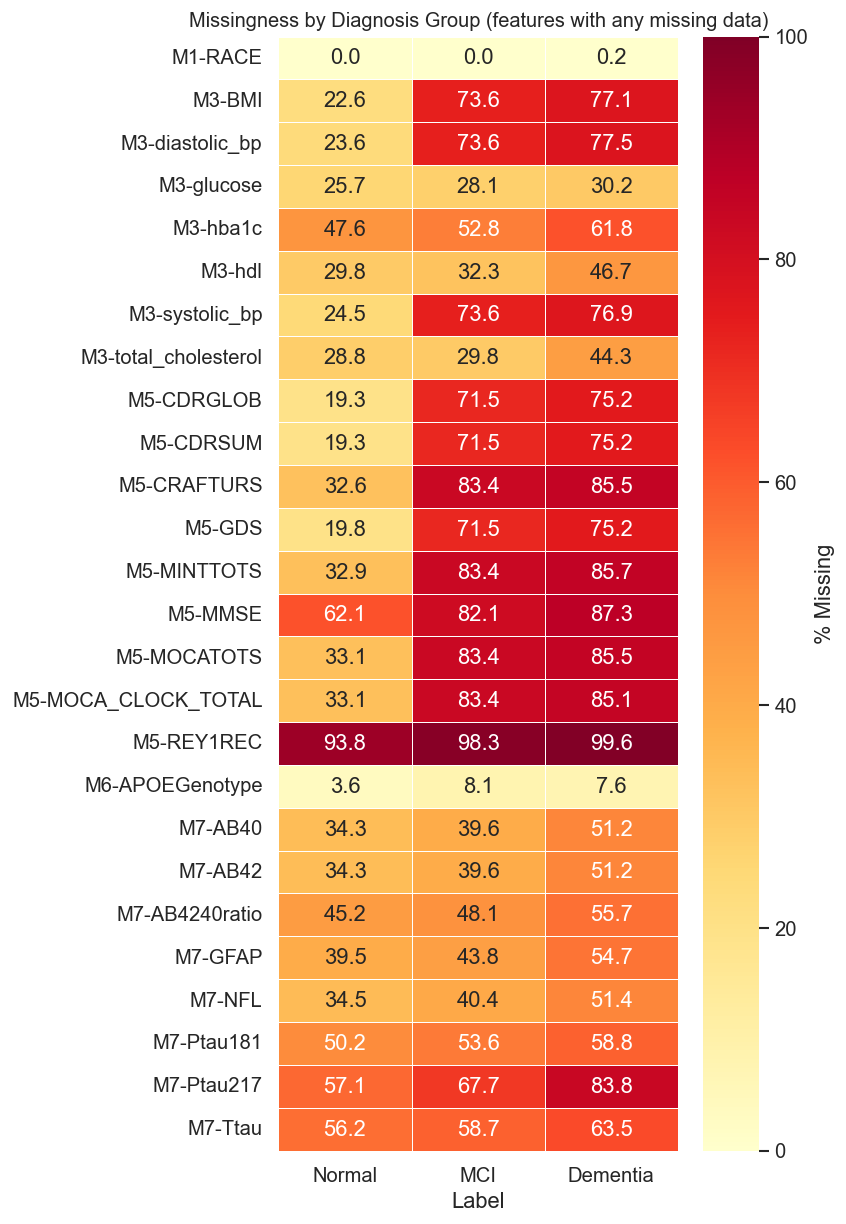

In [43]:
# Check if missingness differs across diagnosis groups for key modalities
label_map = obs.set_index("subid")["label"]

miss_by_label = []
for name, df in modalities.items():
    feat_cols = [c for c in df.columns if c != "subid"]
    for col in feat_cols:
        merged = df[["subid", col]].copy()
        merged["label"] = merged["subid"].map(label_map)
        for label in ["Normal", "MCI", "Dementia"]:
            sub = merged[merged["label"] == label]
            n_miss = sub[col].isna().sum()
            pct = 100 * n_miss / len(sub) if len(sub) > 0 else 0
            miss_by_label.append({"Modality": name.split(" – ")[0], "Feature": col,
                                  "Label": label, "% Missing": round(pct, 1)})

miss_label_df = pd.DataFrame(miss_by_label)

# Only show features with >0% missing in at least one group
has_missing = miss_label_df.groupby("Feature")["% Missing"].max()
features_with_missing = has_missing[has_missing > 0].index.tolist()
miss_label_filtered = miss_label_df[miss_label_df["Feature"].isin(features_with_missing)]

# Pivot for heatmap
pivot = miss_label_filtered.pivot_table(index=["Modality", "Feature"], columns="Label", values="% Missing")
pivot = pivot.reindex(columns=["Normal", "MCI", "Dementia"])

fig, ax = plt.subplots(figsize=(7, max(4, len(pivot) * 0.4)))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", vmin=0, vmax=100,
            linewidths=0.5, ax=ax, cbar_kws={"label": "% Missing"})
ax.set_title("Missingness by Diagnosis Group (features with any missing data)", fontsize=12)
ax.set_ylabel("")
plt.tight_layout()
plt.show()

---
## 6. Summary

| Aspect | Detail |
|--------|--------|
| **Cohort size** | 1,192 patients |
| **Labels** | Normal, MCI, Dementia (3-class) |
| **Modalities** | 7 (Demographics, Comorbidities, Lab Tests, Medications, Cognitive Scores, APOE, Proteins) |
| **Total features** | 55 across all modalities |
| **Binary modalities** | M1 (partial), M2, M4 – no missing values |
| **Continuous modalities** | M3, M5, M6, M7 – substantial missingness (6%–97%) |
| **Most complete** | M2 (Comorbidities), M4 (Medications) – 0% missing |
| **Most sparse** | M5 (Cognitive Scores) – up to 97% missing (REY1REC) |